In [ ]:
library(dplyr)
library(data.table)
library(Matrix)
library(Seurat)
library(ggplot2)
library(SeuratObject) 
library(SeuratDisk)
library(future)
options(future.globals.maxSize = 500 * 1024 ^ 3)
options(warn = 0)
library(pheatmap)
library(grid)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘data.table’


The following objects are masked from ‘package:dplyr’:

    between, first, last


Attaching SeuratObject

Registered S3 method overwritten by 'SeuratDisk':
  method            from  
  as.sparse.H5Group Seurat



In [ ]:
obj <- readRDS('/data/work/毕业文章/Figure2/Cochlea-SGN亚型/Cochlea-SGN注释/SGN&Glia/SGN出图/提纯/Merge-SGN-Final.rds')

In [ ]:
obj

An object of class Seurat 
67980 features across 232 samples within 2 assays 
Active assay: RNA (65980 features, 0 variable features)
 1 other assay present: integrated
 2 dimensional reductions calculated: pca, umap

In [ ]:
Idents(obj) <- 'subtype_Final'
id <- 'Merge-Cochlea-SGN'
Fib_markers <- FindAllMarkers(obj, only.pos = TRUE)

Fib_markers <- Fib_markers %>%
  group_by(cluster) %>%
  dplyr::filter(avg_log2FC > 0.25)

write.csv(Fib_markers, paste0(id, '.markers_filter-high.csv'), row.names = F)

Calculating cluster 2.SGN-Ic

Calculating cluster 3.SGN-Ib

Calculating cluster 4.SGN-Ia

Calculating cluster 5.SGN-II



In [ ]:
colorlist <- c(
"#FFFF00","#1CE6FF","#FF34FF","#FF4A46","#008941",
"#006FA6","#A30059","#00C2A0","#FFAA92","#FF90C9",
"#FF2F80","#BA0900","#6B7900","#00A087FF","#4DBBD5FF",
"#E64B35FF","#3C5488FF","#F38400","#A1CAF1","#F99379",
"#604E97","#F6A600","#F99379","#FF1493","#FF00FF",
"#A020F0","#63B8FF","#008B8B","#54FF9F","#00FF00",
"#76EE00","#FFF68F","#DC143C","#0000FF","#20B2AA",
"#FFA500","#9370DB","#98FB98","#F08080","#1E90FF",
"#7CFC00","#FFFF00","#808000","#FF00FF","#FA8072",
"#7B68EE","#9400D3","#800080","#A0522D","#D2B48C",
"#D2691E","#87CEEB","#40E0D0","#5F9EA0","#FF1493",
"#0000CD","#008B8B","#FFE4B5","#8A2BE2","#228B22",
"#E9967A","#4682B4"
)

In [ ]:
table(obj$subtype_Final)


SGN-Ia SGN-Ib SGN-Ic SGN-II 
    54     73     69     36 

In [ ]:
colorlist <- c(
  "SGN-Ia"       = "#FDB45B",
  "SGN-Ib"      = "#68C1D9",
  "SGN-Ic" = "#B8DFAF",
  "SGN-II"            = "#D92E92"
)

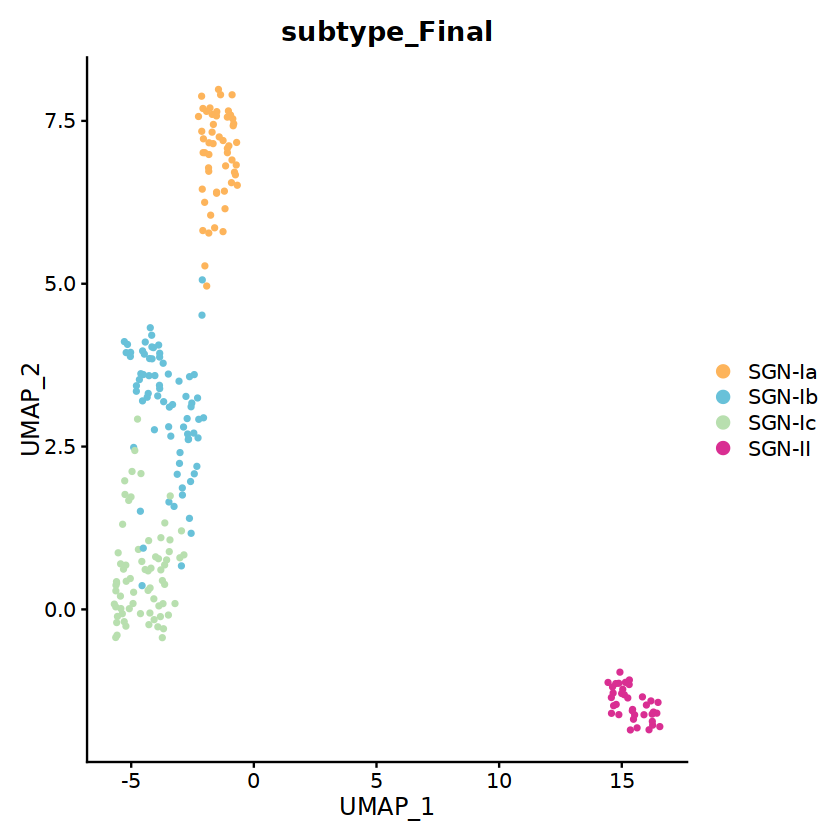

In [ ]:
p <- DimPlot(
  obj,
  label=FALSE,
  reduction="umap",
  cols=colorlist,
  group.by="subtype_Final",
  pt.size=1
)
p
ggsave("Merge-SGN_UMAP-Ann.pdf",p,width = 6,height = 6)

In [ ]:
markers <- c(
#2.SGN-II
"Th","Prph","Gata3",
#5.SGN-Ic
"Lypd1","Grm8","Kcnip2","Pou4f1",
#4.SGN-Ib
"Ttn","Sema3d","Calb1",
#6.SGN-Ia
"Calb2","Epha4", "Sema3e")
markers <- unique(markers)

In [ ]:
id <- 'Merge-SGN亚群'

[1] 13

Warning message:
“Scaling data with a low number of groups may produce misleading results”
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for size is already present.
Adding another scale for size, which will replace the existing scale.


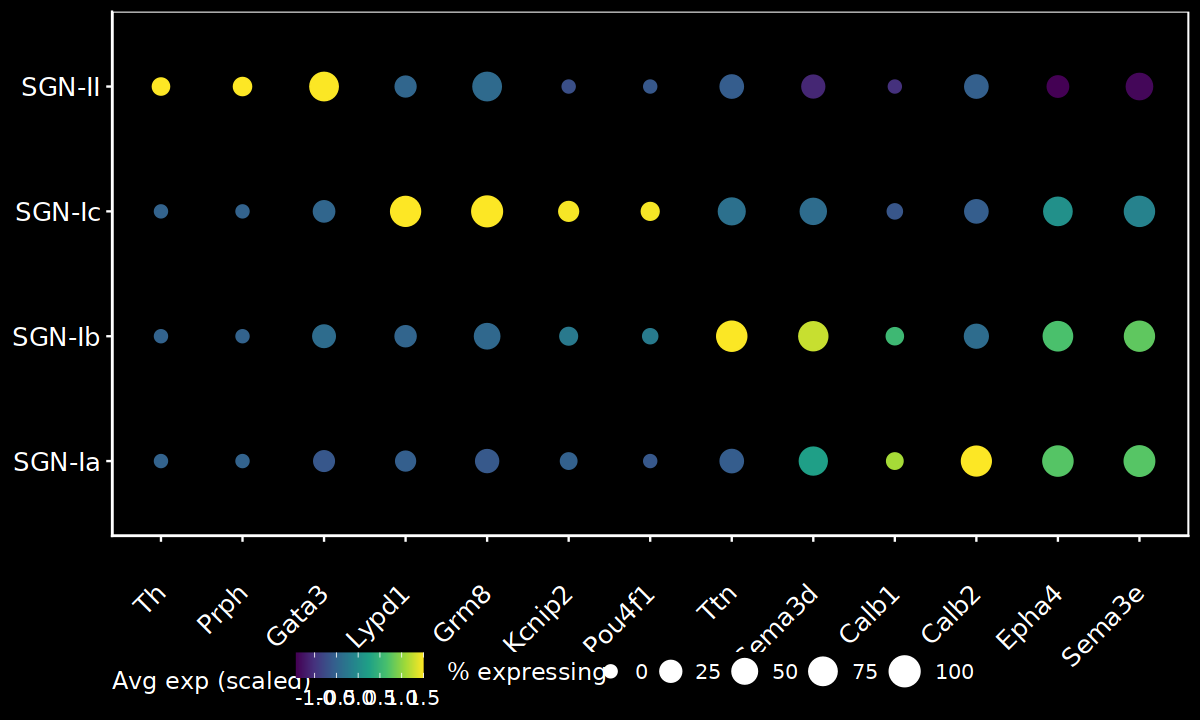

In [ ]:
options(repr.plot.width=10,repr.plot.height=6)
Epi <- obj
markers <- markers[markers %in% rownames(Epi[["RNA"]])]
length(markers)
p <- DotPlot(
  object = Epi,
  features = unique(markers),   # 基因顺序 = markers 首次出现顺序
  dot.scale = 5,
  scale.min = 0,
  scale.max = 100,
  group.by = 'subtype_Final'  # 使用celltype列
) +
  scale_color_gradientn(
    colours = colorRampPalette(c("#440154", "#46327E", "#365C8D", "#277F8E", 
                                 "#1FA187", "#4AC16D", "#A0DA39", "#FDE725"))(100)
  ) +
  labs(x = NULL, y = NULL) +
  guides(
    colour = guide_colourbar(order = 1, title = "Avg exp (scaled)"),
    size = guide_legend(order = 2, title = "% expressing",
                        override.aes = list(colour = "white", fill = "white", alpha = 1))
  ) +
  scale_size_continuous(limits = c(0, 100), breaks = c(0, 25, 50, 75, 100), range = c(3, 8)) +
  theme(
    panel.background = element_rect(fill = "black", colour = NA),
    plot.background = element_rect(fill = "black", colour = NA),
    panel.grid = element_blank(),
    axis.text.x = element_text(angle = 45, hjust = 1, vjust = 0.5, colour = "white", size = 15),
    axis.text.y = element_text(colour = "white", size = 15),
    axis.ticks = element_line(colour = "white"),
    axis.line = element_line(colour = "white"),
    panel.border = element_rect(colour = "white", fill = NA),
    legend.position = "bottom",
    legend.direction = "horizontal",
    legend.background = element_rect(fill = "black", colour = NA),
    legend.title = element_text(colour = "white"),
    legend.text = element_text(colour = "white")
  )

print(p)

ggsave(filename = paste0(id, '_DotPlot.pdf'), 
       plot = p, width = 9, height = 6)


In [ ]:
expression_data <-  GetAssayData(obj, assay = "RNA", slot = "data")  # 使用标准化数据

# 根据 RCTD_multi_celltype 分组并计算平均表达量
avg_expression <- AverageExpression(
  obj, 
  assays = "RNA", 
  group.by = "subtype_Final"
)$RNA
avg_expression <- log1p(avg_expression)
# 计算基因表达的相关性矩阵
correlation_matrix <- cor(avg_expression, method = "pearson")

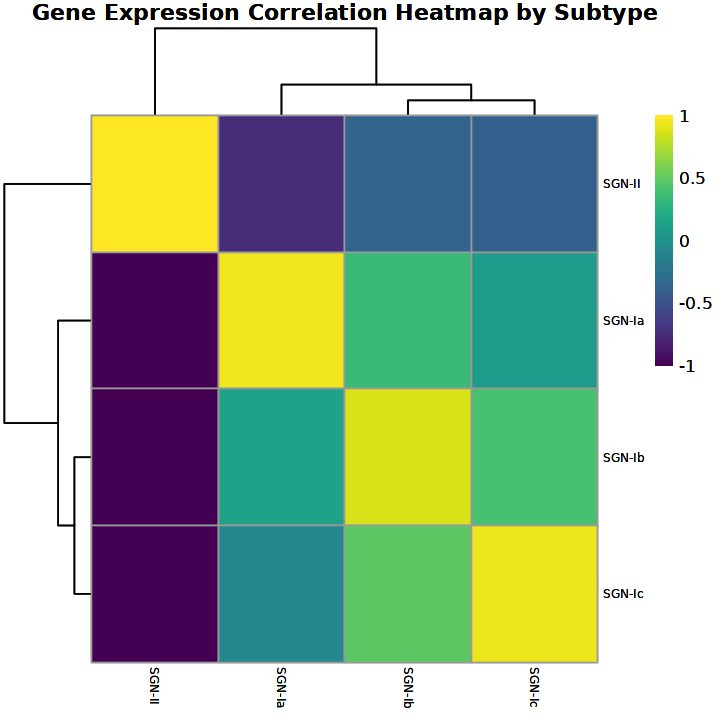

In [ ]:

# 设置绘图选项
options(repr.plot.width = 6, repr.plot.height = 6)

# 使用 pheatmap 绘制热图，调整颜色范围
p <- pheatmap(
  correlation_matrix,
  main = "Gene Expression Correlation Heatmap by Subtype",
  color = viridisLite::viridis(100),
  fontsize_row = 7,
  fontsize_col = 7,
breaks = seq(-1, 1, length.out = 101),
  scale = "row",  # 不进行行或列缩放
  cluster_col = TRUE,
  cluster_row = TRUE,
  angle_row = 45 # 行标签倾斜 45 度  
)
print(p)
# 保存热图
ggsave(paste0(id, '_correlation_heatmap.pdf'), p, width = 8, height = 8)

In [ ]:
table(obj$subtype_Final)


SGN-Ia SGN-Ib SGN-Ic SGN-II 
    54     73     69     36 

In [ ]:
Fib_markers <- read.csv('Merge-Cochlea-SGN.markers_filter-high.csv')

In [ ]:
SGNII_top30 <- Fib_markers %>%
  filter(cluster=="5.SGN-II") %>%
  arrange(desc(avg_log2FC)) %>%
  slice_head(n=30)

markers <- SGNII_top30$gene

markers

[1] "Pde1c"              "Gm72623"            "Efna5"             
 [4] "Prune2"             "Grik3"              "Tnr"               
 [7] "mt-Rnr1"            "Rn18s-rs5"          "Sorcs3"            
[10] "Ralyl"              "mt-Rnr2"            "ENSMUSG00000127915"
[13] "Fnbp1l"             "Arhgap24"           "Gm45589"           
[16] "Cblb"               "Dok6"               "Gm19064"           
[19] "Hs3st4"             "Gm64942"            "Adarb2"            
[22] "Epha6"              "Kirrel3"            "Cpne8"             
[25] "Agpat3"             "Gm58936"            "Rph3a"             
[28] "Gm26871"            "Cacna2d2"           "Gldn"

In [ ]:
markers <- c(
"Gata3","Lypd1","Grm8","Ttn","Calb2","Sema3e")
markers <- unique(markers)

In [ ]:
pdf("SGn-VlnPlot-筛选.pdf",width=10,height=9)

for(i in seq(1,length(markers),by=4)){
  genes <- markers[i:min(i+3,length(markers))]

  p <- VlnPlot(
    obj,
    features=genes,
    group.by="subtype_Final",
    pt.size=0,
    combine=FALSE
  )

  print(patchwork::wrap_plots(p,ncol=2))
}

dev.off()

pdf 
  2

In [ ]:
obj <- readRDS('/data/work/毕业文章/Figure2/Cochlea-SGN亚型/Cochlea-SGN注释/SGN&Glia/Glia-提纯/Glia-亚群细分/Merge-Glia-Final.rds')

In [ ]:
obj

An object of class Seurat 
68980 features across 1913 samples within 2 assays 
Active assay: RNA (65980 features, 0 variable features)
 1 other assay present: integrated
 2 dimensional reductions calculated: pca, umap

In [ ]:
head(obj)

,orig.ident,nCount_RNA,nFeature_RNA,sample,percent.mt,RNA_snn_res.0.5,seurat_clusters,source,SN,RNA_snn_res.0.8,⋯,RNA_snn_res.0.3,integrated_snn_res.0.3,celltype,celltype_0813,scDblFinder.class,scDblFinder.score,integrated_snn_res.0.7,subtype,integrated_snn_res.1,Glia_subtype
,<chr>,<dbl>,<int>,<chr>,<dbl>,<chr>,<fct>,<chr>,<chr>,<chr>,⋯,<chr>,<fct>,<chr>,<fct>,<fct>,<dbl>,<fct>,<chr>,<fct>,<chr>
15520_4,SeuratProject,5857,2394,Y01818K9,0.17073587,NA,8,StereoCell,Y01818K9,0,⋯,NA,2,1.SGN,2.SGN,singlet,0.14358014,8,8.Myelinating Schwann cell,8,2.nmSC2
11104_4,SeuratProject,8519,2519,Y01818K9,0.25824627,NA,2,StereoCell,Y01818K9,13,⋯,NA,2,1.SGN,2.SGN,singlet,0.02045357,8,8.Myelinating Schwann cell,2,2.nmSC2
8109_4,SeuratProject,17805,4648,Y01818K9,0.15164280,NA,2,StereoCell,Y01818K9,5,⋯,NA,2,1.SGN,2.SGN,singlet,0.05516464,8,8.Myelinating Schwann cell,2,2.nmSC2
6674_4,SeuratProject,3313,1502,Y01818K9,0.09055237,NA,3,StereoCell,Y01818K9,3,⋯,NA,1,9.Schwann_Cells,9.Schwann_cells,singlet,0.02173292,5,5.Myelinating Schwann cell,3,3.nmSC1
11383_4,SeuratProject,6129,2432,Y01818K9,0.06526350,NA,2,StereoCell,Y01818K9,0,⋯,NA,2,1.SGN,2.SGN,singlet,0.01340694,8,8.Myelinating Schwann cell,2,2.nmSC2
11753_4,SeuratProject,8527,3018,Y01818K9,0.12900199,NA,2,StereoCell,Y01818K9,1,⋯,NA,2,1.SGN,2.SGN,singlet,0.30698338,8,8.Myelinating Schwann cell,2,2.nmSC2
12996_4,SeuratProject,9964,3338,Y01818K9,0.17061421,NA,2,StereoCell,Y01818K9,13,⋯,NA,2,22.Satellite_Glial_Cells,22.Satellite Glial Cells,singlet,0.13024451,8,8.Myelinating Schwann cell,2,2.nmSC2
16995_4,SeuratProject,4224,1960,Y01818K9,0.09469697,NA,6,StereoCell,Y01818K9,0,⋯,NA,1,9.Schwann_Cells,9.Schwann_cells,singlet,0.06030093,5,5.Myelinating Schwann cell,6,6.SGC
14439_4,SeuratProject,7515,2753,Y01818K9,0.10645376,NA,2,StereoCell,Y01818K9,0,⋯,NA,2,1.SGN,2.SGN,singlet,0.31819069,8,8.Myelinating Schwann cell,2,2.nmSC2


In [ ]:
Epi <- obj

In [ ]:
Idents(Epi) <- "Glia_subtype"
DefaultAssay(Epi) <- "RNA"

Fib_markers <- FindAllMarkers(
  Epi,
  only.pos=TRUE,
  logfc.threshold=0.5,
  min.pct=0.2
) 
write.csv(Fib_markers, 'Merge-Glia-Final-marker.csv')

Calculating cluster 2.nmSC2

Calculating cluster 3.nmSC1

Calculating cluster 6.SGC

Calculating cluster 9.Oligodendrocytes

Calculating cluster 7.mSC1



In [ ]:
table(obj$Glia_subtype)


            mSC1            nmSC1            nmSC2 Oligodendrocytes 
             268              521              741               39 
             SGC 
             344 

In [ ]:
id <- 'Merge-Cochlea-Glia-Final'
DefaultAssay(obj) <- 'RNA'

In [ ]:
colorlist <- c(
  "mSC1"         = "#FFE66D",
  "nmSC1"       = "#FDB45B",
  "nmSC2"      = "#68C1D9",
  "Oligodendrocytes" = "#B8DFAF",
  "SGC"            = "#D92E92"
)

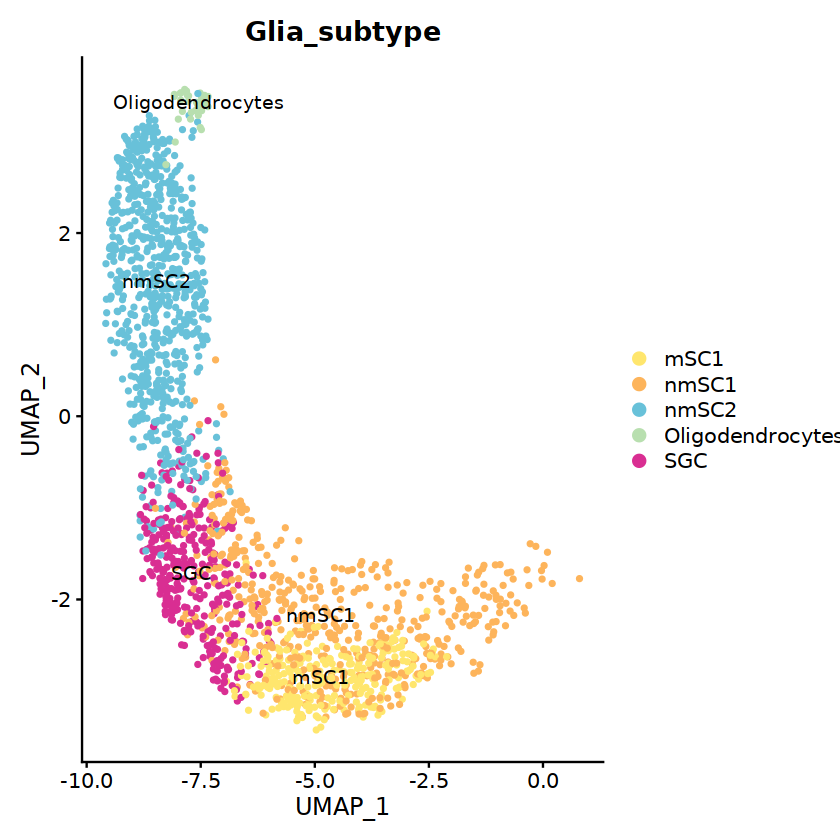

In [ ]:
p <- DimPlot(
  obj,
  label=TRUE,
  reduction="umap",
  cols=colorlist,
  group.by="Glia_subtype",
  pt.size=1
)
p
ggsave("Merge-Glia_UMAP.pdf",p,width = 10,height = 8)

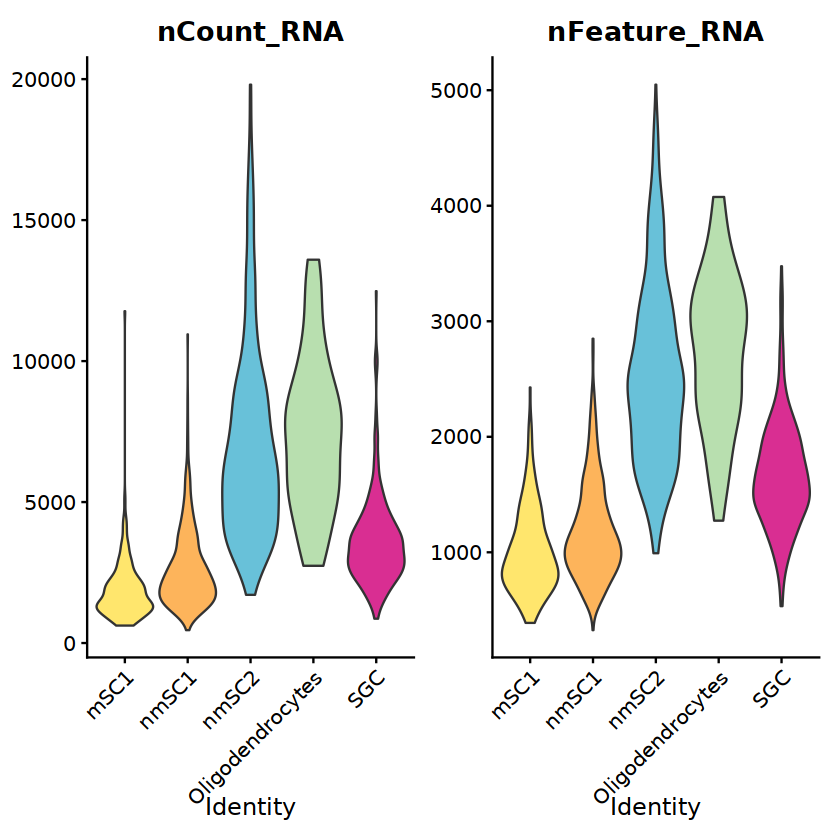

In [ ]:
p <- VlnPlot(
  obj,
  features=c("nCount_RNA",'nFeature_RNA'),
  group.by="Glia_subtype",
  cols=colorlist,
  pt.size=0
)+
theme(axis.text.x=element_text(angle=45,hjust=1))
p
ggsave("Merge-Glia_Violin.pdf",p,width = 10,height = 8)

In [ ]:
markers <- c(
"Ncmap","Prx","Drp2","Pmp22",
"Scn7a","Slc35f1","Glul",
"Dpp6","Pid1","Cntnap2","Csmd1","Ngfr","Cd44",
"Myrf","Mog","Mobp","Ermn","Aspa","Olig2",
"Igfbp6","Slc1a3","Npas3","Pde1c","Lama1"
)

[1] 24

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for size is already present.
Adding another scale for size, which will replace the existing scale.


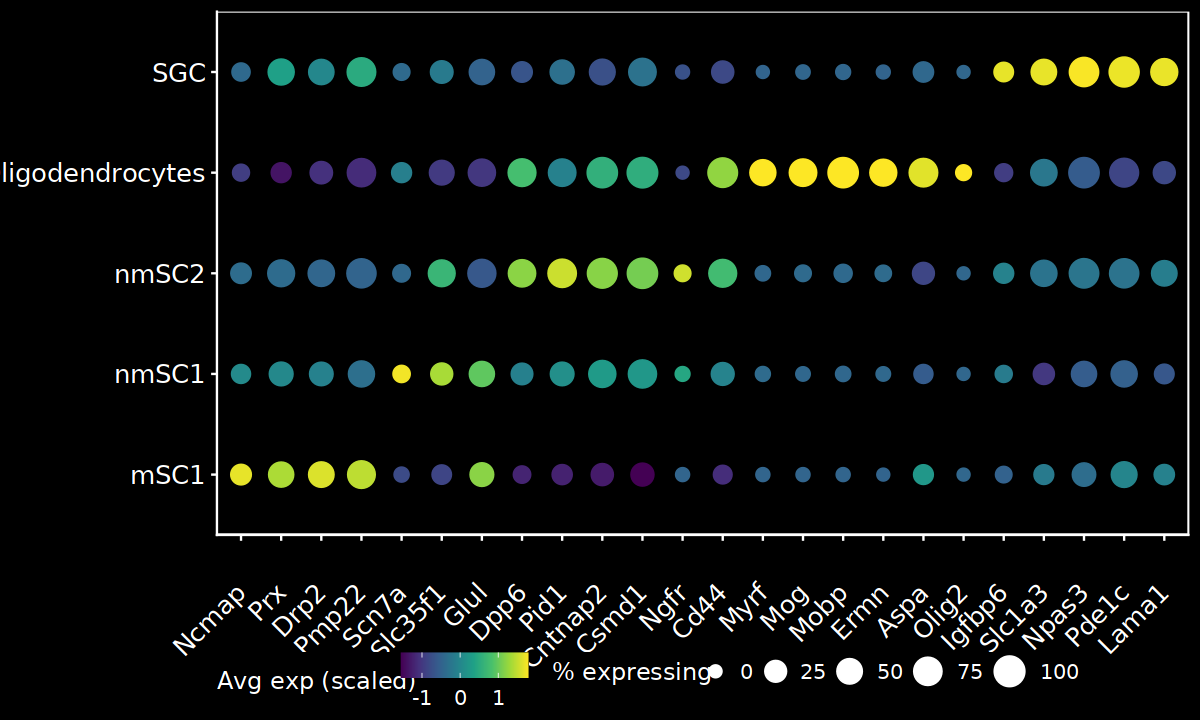

In [ ]:
options(repr.plot.width=10,repr.plot.height=6)
Epi <- obj
markers <- markers[markers %in% rownames(Epi[["RNA"]])]
length(markers)
p <- DotPlot(
  object = Epi,
  features = unique(markers),   # 基因顺序 = markers 首次出现顺序
  dot.scale = 5,
  scale.min = 0,
  scale.max = 100,
  group.by = 'Glia_subtype'  # 使用celltype列
) +
  scale_color_gradientn(
    colours = colorRampPalette(c("#440154", "#46327E", "#365C8D", "#277F8E", 
                                 "#1FA187", "#4AC16D", "#A0DA39", "#FDE725"))(100)
  ) +
  labs(x = NULL, y = NULL) +
  guides(
    colour = guide_colourbar(order = 1, title = "Avg exp (scaled)"),
    size = guide_legend(order = 2, title = "% expressing",
                        override.aes = list(colour = "white", fill = "white", alpha = 1))
  ) +
  scale_size_continuous(limits = c(0, 100), breaks = c(0, 25, 50, 75, 100), range = c(3, 8)) +
  theme(
    panel.background = element_rect(fill = "black", colour = NA),
    plot.background = element_rect(fill = "black", colour = NA),
    panel.grid = element_blank(),
    axis.text.x = element_text(angle = 45, hjust = 1, vjust = 0.5, colour = "white", size = 15),
    axis.text.y = element_text(colour = "white", size = 15),
    axis.ticks = element_line(colour = "white"),
    axis.line = element_line(colour = "white"),
    panel.border = element_rect(colour = "white", fill = NA),
    legend.position = "bottom",
    legend.direction = "horizontal",
    legend.background = element_rect(fill = "black", colour = NA),
    legend.title = element_text(colour = "white"),
    legend.text = element_text(colour = "white")
  )

print(p)

ggsave(filename = paste0(id, '_DotPlot.pdf'), 
       plot = p, width = 15, height = 4)

In [ ]:
expression_data <-  GetAssayData(obj, assay = "RNA", slot = "data")  # 使用标准化数据

# 根据 RCTD_multi_celltype 分组并计算平均表达量
avg_expression <- AverageExpression(
  obj, 
  assays = "RNA", 
  group.by = "Glia_subtype"
)$RNA
avg_expression <- log1p(avg_expression)
# 计算基因表达的相关性矩阵
correlation_matrix <- cor(avg_expression, method = "pearson")

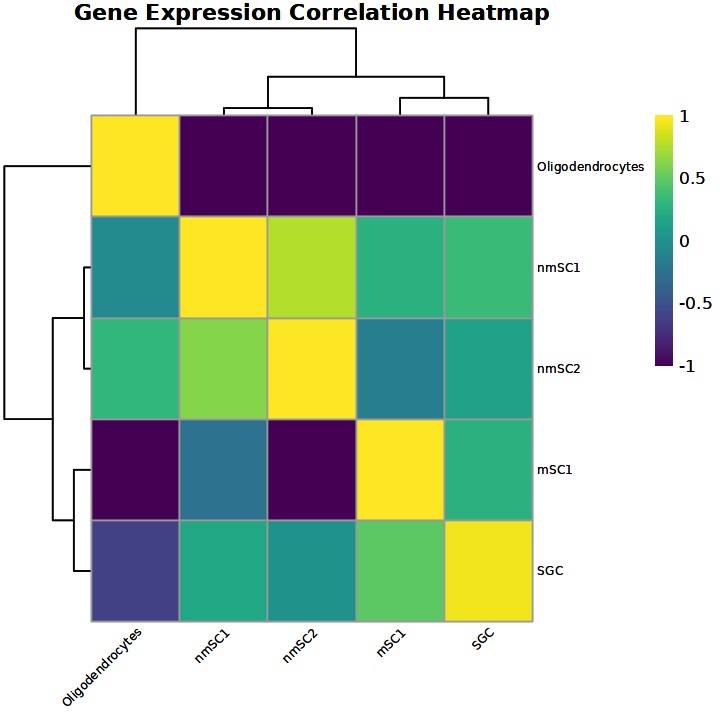

In [ ]:
options(repr.plot.width=6,repr.plot.height=6)

hc <- hclust(as.dist(1-correlation_matrix))

p <- pheatmap(
  correlation_matrix,
  main="Gene Expression Correlation Heatmap",
  color=viridisLite::viridis(100),
  fontsize_row=7,
  fontsize_col=7,
  breaks=seq(-1,1,length.out=101),
  scale="column",
  cluster_rows=hc,
  cluster_cols=hc,
  angle_col=45
)

print(p)
ggsave(paste0(id,"_correlation_heatmap.pdf"),p,width=8,height=8)

In [ ]:
markers <- c(
"Prx","Drp2","Pmp22","Slc35f1","Glul","Csmd1",
"Dpp6","Pid1","Cntnap2","Cd44",
"Myrf","Mog","Mobp","Ermn","Aspa",
"Slc1a3","Npas3","Pde1c","Lama1"
)

In [ ]:
pdf("Glia-VlnPlot-筛选.pdf",width=10,height=9)

for(i in seq(1,length(markers),by=4)){
  genes <- markers[i:min(i+3,length(markers))]

  p <- VlnPlot(
    obj,
    features=genes,
    group.by="Glia_subtype",
    pt.size=0,
    cols=colorlist,
    combine=FALSE
  )

  print(patchwork::wrap_plots(p,ncol=2))
}

dev.off()

pdf 
  2

In [ ]:
obj <- readRDS('Merge-Epi-Final-V2.rds')

In [ ]:
Idents(obj) <- 'subtype_Final'

In [ ]:
obj
head(obj,3)

An object of class Seurat 
68980 features across 3588 samples within 2 assays 
Active assay: RNA (65980 features, 0 variable features)
 1 other assay present: integrated
 2 dimensional reductions calculated: pca, umap

,orig.ident,nCount_RNA,nFeature_RNA,sample,percent.mt,RNA_snn_res.0.5,seurat_clusters,source,SN,RNA_snn_res.0.8,⋯,RNA_snn_res.0.3,integrated_snn_res.0.3,celltype,celltype_0813,scDblFinder.class,scDblFinder.score,integrated_snn_res.0.5,integrated_snn_res.0.7,integrated_snn_res.0.6,subtype_Final
,<chr>,<dbl>,<int>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<fct>,<chr>,<fct>,<fct>,<dbl>,<fct>,<fct>,<fct>,<chr>
20138_4,SeuratProject,1257,758,Y01818K9,0.0000000,NA,3,StereoCell,Y01818K9,6,⋯,NA,3,13.Stria_Vascularis_Marginal_Cells,13.SV-MC,singlet,1.165554e-05,2,3,3,SV-MC
1720_4,SeuratProject,3417,1514,Y01818K9,0.2048581,NA,11,StereoCell,Y01818K9,6,⋯,NA,1,6.Reissner_Membrane,6.RM,singlet,2.260749e-03,5,6,5,RM
16102_4,SeuratProject,7462,2945,Y01818K9,0.2814259,NA,2,StereoCell,Y01818K9,6,⋯,NA,2,13.Stria_Vascularis_Marginal_Cells,13.SV-MC,singlet,1.750573e-01,1,0,0,SV-MC


In [ ]:
colorlist <- c(
"#FFFF00","#1CE6FF","#FF34FF","#FF4A46","#008941",
"#006FA6","#A30059","#00C2A0","#FFAA92","#FF90C9",
"#FF2F80","#BA0900","#6B7900","#00A087FF","#4DBBD5FF",
"#E64B35FF","#3C5488FF","#F38400","#A1CAF1","#F99379",
"#604E97","#F6A600","#F99379","#FF1493","#FF00FF",
"#A020F0","#63B8FF","#008B8B","#54FF9F","#00FF00",
"#76EE00","#FFF68F","#DC143C","#0000FF","#20B2AA",
"#FFA500","#9370DB","#98FB98","#F08080","#1E90FF",
"#7CFC00","#FFFF00","#808000","#FF00FF","#FA8072",
"#7B68EE","#9400D3","#800080","#A0522D","#D2B48C",
"#D2691E","#87CEEB","#40E0D0","#5F9EA0","#FF1493",
"#0000CD","#008B8B","#FFE4B5","#8A2BE2","#228B22",
"#E9967A","#4682B4"
)

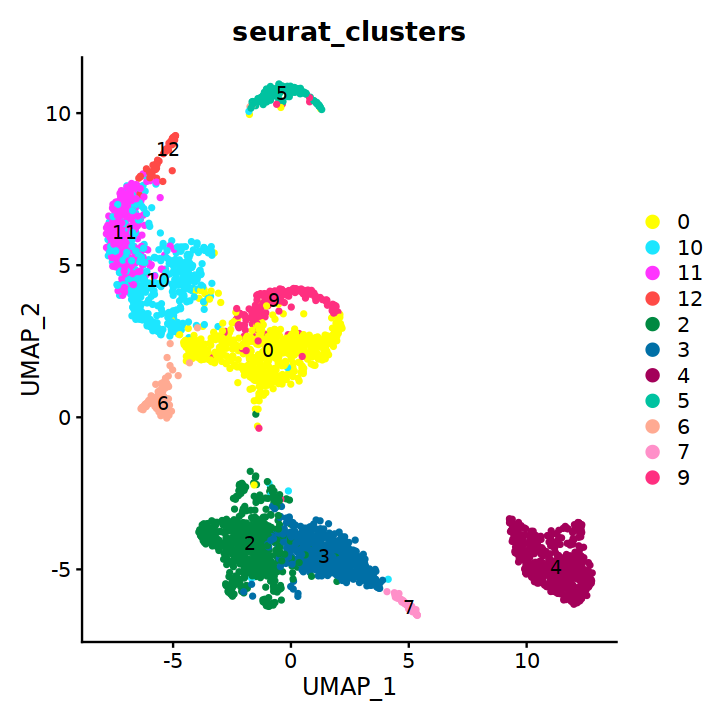

In [ ]:
p <- DimPlot(
  obj,
  label=TRUE,
  reduction="umap",
  cols=colorlist,
  group.by="seurat_clusters",
  pt.size=1
)
p

In [ ]:
Idents(obj) <- 'subtype_Final'
id <- 'Merge-Cochlea-Epi'
Fib_markers <- FindAllMarkers(obj, only.pos = TRUE)

Fib_markers <- Fib_markers %>%
  group_by(cluster) %>%
  dplyr::filter(avg_log2FC > 0.25)

write.csv(Fib_markers, paste0(id, '.markers_filter-high.csv'), row.names = F)

Calculating cluster SV-MC

Calculating cluster RM

Calculating cluster IPhC_IBC

Calculating cluster Spindle cells

Calculating cluster TBC

Calculating cluster ISC_OSC

Calculating cluster Hair Cells

Calculating cluster SV-Basal



In [ ]:
subtype_order <- c(
  "SV-MC",
  "ISC_OSC",
  "SV-Basal",
  "Spindle cells",
  "RM",
  "SCs",
  "IPhC_IBC",
  "Hair Cells",
  "TBC"
)

obj$subtype_Final <- factor(
  obj$subtype_Final,
  levels=subtype_order
)

In [ ]:
colorlist <- c(
  "SV-MC"         = "#FFE66D",
  "ISC_OSC"       = "#FDB45B",
  "SV-Basal"      = "#68C1D9",
  "Spindle cells" = "#B8DFAF",
  "RM"            = "#D92E92",
  "SCs"           = "#F6CFD4",
  "IPhC_IBC"      = "#9FC5E8",
  "Hair Cells"    = "#C7B5E3",
  "TBC"           = "#A9D18E"
)

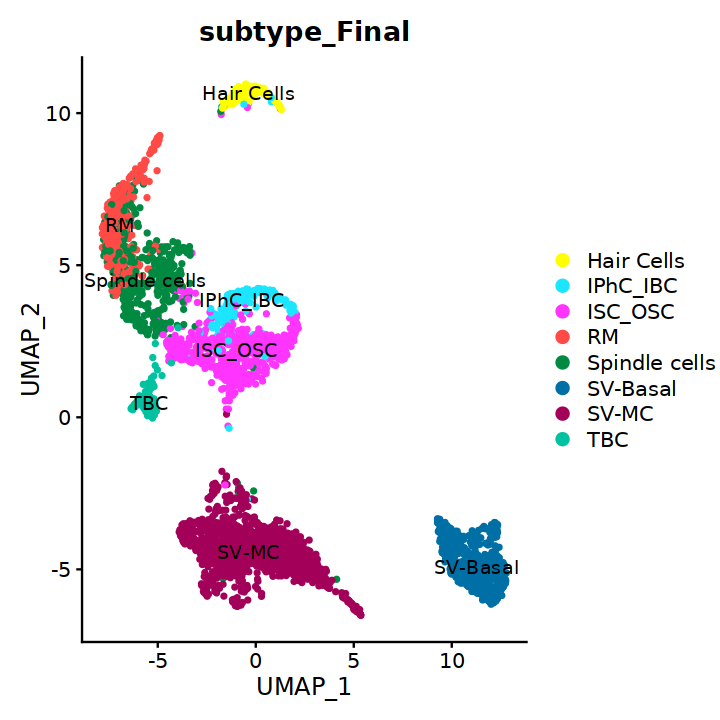

In [ ]:
options(repr.plot.width=6,repr.plot.height=6)
p <- DimPlot(
  obj,
  label=TRUE,
  reduction="umap",
  cols=colorlist,
  group.by="subtype_Final",
  pt.size=1
)
p
ggsave("Merge-Epi_UMAP.pdf",p,width = 10,height = 8)

In [ ]:
expression_data <-  GetAssayData(obj, assay = "RNA", slot = "data")  # 使用标准化数据

# 根据 RCTD_multi_celltype 分组并计算平均表达量
avg_expression <- AverageExpression(
  obj, 
  assays = "RNA", 
  group.by = "subtype_Final"
)$RNA
avg_expression <- log1p(avg_expression)
# 计算基因表达的相关性矩阵
correlation_matrix <- cor(avg_expression, method = "pearson")

In [ ]:
options(repr.plot.width=6,repr.plot.height=6)

hc <- hclust(as.dist(1-correlation_matrix))

p <- pheatmap(
  correlation_matrix,
  main="Gene Expression Correlation Heatmap",
  color=viridisLite::viridis(100),
  fontsize_row=7,
  fontsize_col=7,
  breaks=seq(-1,1,length.out=101),
  scale="column",
  cluster_rows=hc,
  cluster_cols=hc,
  angle_col=45
)

print(p)
ggsave(paste0(id,"_correlation_heatmap.pdf"),p,width=8,height=8)

In [ ]:
id <- 'Merge-Cochlea-Epi亚群注释'
DefaultAssay(obj) <- 'RNA'
Epi <- obj

In [ ]:
markers <- c(
#SV-MC
"Kcnq1","Esrrb","Kcne1","Stac","Dclk1","Cacnb2",
#ISC_OSC
"Epyc","Slc26a4","Lgr5","Rspo2",
#SV-Basal
"Cldn11","Atp6v0a4","Nr2f2",
#Spindle cells
"Anxa1","Dpp10",
#RM
"Slc26a7","Tmem72","Vmo1","Otx2",
#IPhC_IBC
"Dgkb","Klhl14","Nckap5","Slc1a3","Kcnj10",
#SV-IC
#"Dct","Kcnj13",
#Hair Cells
"Pou4f3","Myo7a","Otof","Ptprq","Slc26a5",
#TBC
"Emilin2","Mybpc1","Nav3"
)

[1] 32

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for size is already present.
Adding another scale for size, which will replace the existing scale.


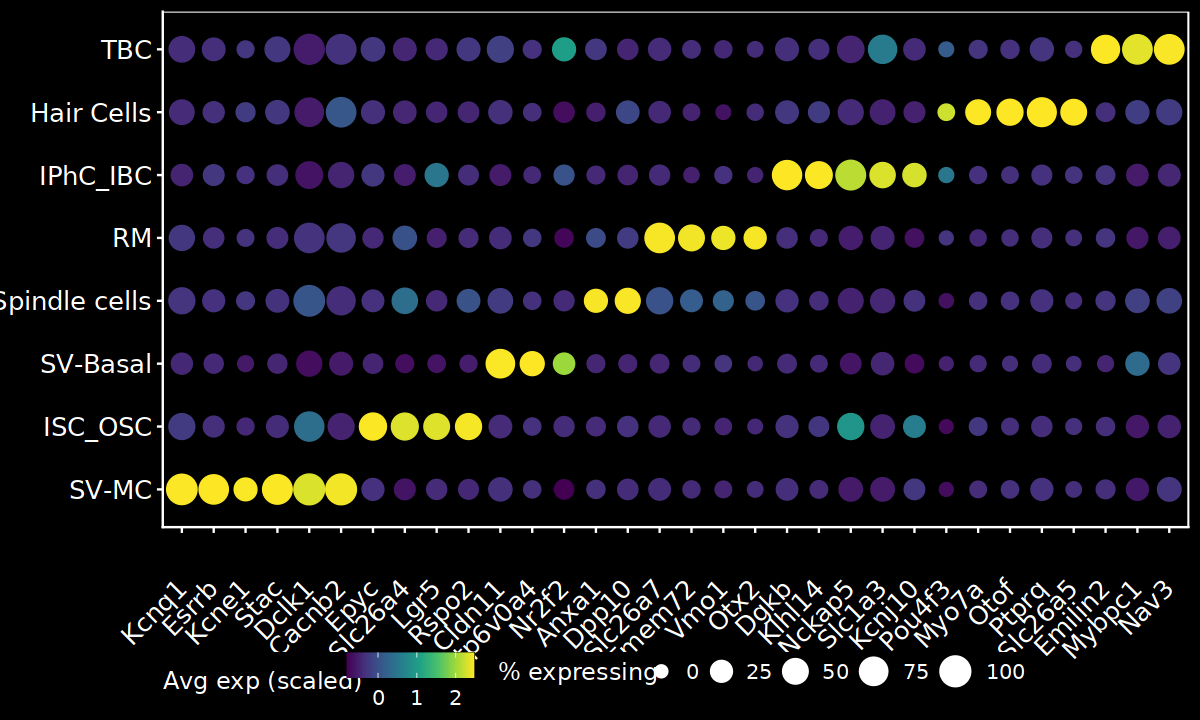

In [ ]:
options(repr.plot.width=10,repr.plot.height=6)
markers <- markers[markers %in% rownames(Epi[["RNA"]])]
length(markers)
p <- DotPlot(
  object = obj,
  features = unique(markers),   # 基因顺序 = markers 首次出现顺序
  dot.scale = 5,
  scale.min = 0,
  scale.max = 100,
  group.by = 'subtype_Final'  # 使用celltype列
) +
  scale_color_gradientn(
    colours = colorRampPalette(c("#440154", "#46327E", "#365C8D", "#277F8E", 
                                 "#1FA187", "#4AC16D", "#A0DA39", "#FDE725"))(100)
  ) +
  labs(x = NULL, y = NULL) +
  guides(
    colour = guide_colourbar(order = 1, title = "Avg exp (scaled)"),
    size = guide_legend(order = 2, title = "% expressing",
                        override.aes = list(colour = "white", fill = "white", alpha = 1))
  ) +
  scale_size_continuous(limits = c(0, 100), breaks = c(0, 25, 50, 75, 100), range = c(3, 8)) +
  theme(
    panel.background = element_rect(fill = "black", colour = NA),
    plot.background = element_rect(fill = "black", colour = NA),
    panel.grid = element_blank(),
    axis.text.x = element_text(angle = 45, hjust = 1, vjust = 0.5, colour = "white", size = 15),
    axis.text.y = element_text(colour = "white", size = 15),
    axis.ticks = element_line(colour = "white"),
    axis.line = element_line(colour = "white"),
    panel.border = element_rect(colour = "white", fill = NA),
    legend.position = "bottom",
    legend.direction = "horizontal",
    legend.background = element_rect(fill = "black", colour = NA),
    legend.title = element_text(colour = "white"),
    legend.text = element_text(colour = "white")
  )

print(p)

ggsave(filename = paste0(id, '_DotPlot.pdf'), 
       plot = p, width = 15, height = 6)

In [ ]:
markers_df <- read.csv("Stereocell-Epi-富集-中筛.csv")
markers <- unique(markers_df$gene)
markers <- markers[markers %in% rownames(Epi[["RNA"]])]

markers_df %>%
  count(cluster,name="n_genes")

length(markers)

cluster,n_genes
<chr>,<int>
Hair Cells,52
ISC_OSC,61
RM,77
SCs,99
SV-Basal,59
SV-MC,103
Spindle cells,15
TBC,49


[1] 477

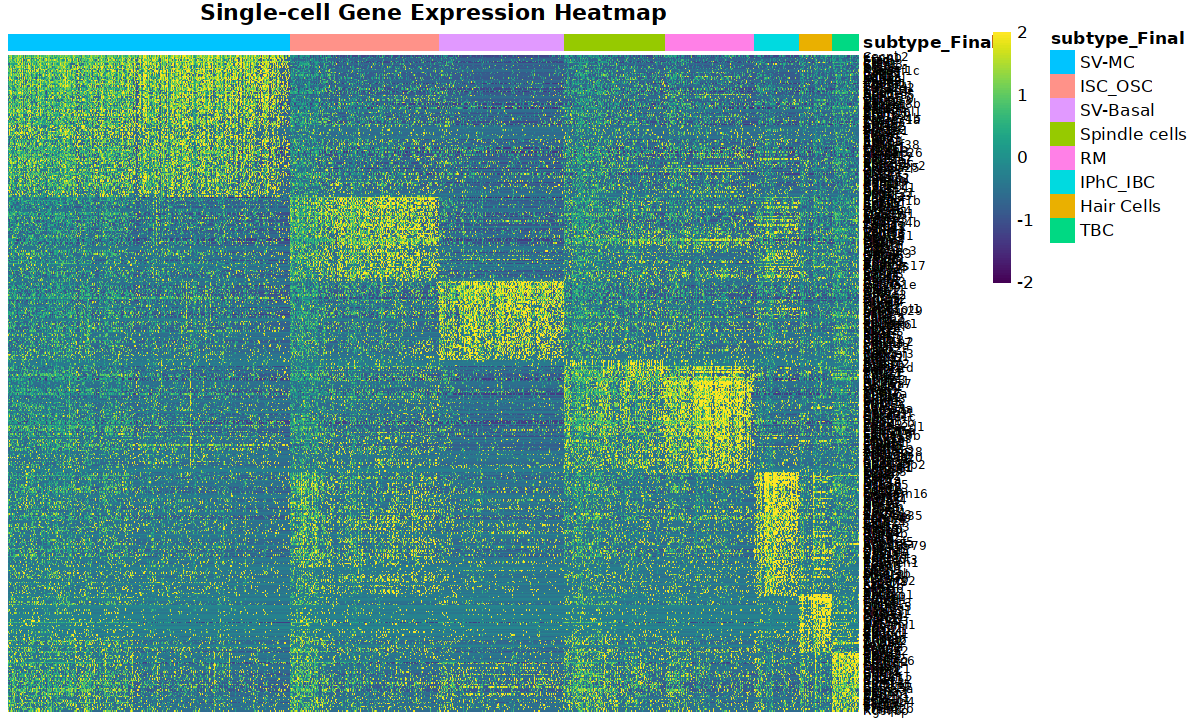

In [ ]:
options(repr.plot.width=10,repr.plot.height=6)
expression_matrix <- GetAssayData(Epi,assay="RNA",slot="data")

markers <- markers[markers %in% rownames(Epi[["RNA"]])]

meta <- Epi@meta.data
cells_order <- rownames(meta)[order(meta$subtype_Final)]

mat <- as.matrix(
  expression_matrix[markers,cells_order,drop=FALSE]
)

mat <- t(scale(t(mat)))
mat[mat > 2] <- 2
mat[mat < -2] <- -2

annotation_col <- data.frame(
  subtype_Final=meta[cells_order,"subtype_Final"]
)
rownames(annotation_col) <- cells_order

p <- pheatmap(
  mat,
  main="Single-cell Gene Expression Heatmap",
  color=viridisLite::viridis(100),
  breaks=seq(-2,2,length.out=101),
  fontsize_row=7,
  show_colnames=FALSE,
  cluster_col=FALSE,
  cluster_row=FALSE,
  annotation_col=annotation_col
)

ggsave(
  paste0(id,"_singlecell_pheatmap.pdf"),
  plot=p,
  width=30,
  height=45
)

In [ ]:
Epi <- obj

In [ ]:
Idents(Epi) <- "subtype_Final"
DefaultAssay(Epi) <- "RNA"

Fib_markers <- FindAllMarkers(
  Epi,
  only.pos=TRUE,
  logfc.threshold=0.5,
  min.pct=0.2
) 
write.csv(Fib_markers, 'Merge-Epi-Final-marker.csv')

Calculating cluster SV-MC

Calculating cluster ISC_OSC

Calculating cluster SV-Basal

Calculating cluster Spindle cells

Calculating cluster RM

Calculating cluster SCs

Calculating cluster Hair Cells

Calculating cluster TBC



In [ ]:
markers_df <- Fib_markers %>%
  dplyr::filter(
    !grepl("^Gm",gene),
    !grepl("^mt-",gene,ignore.case=TRUE),
    !grepl("Rik$",gene),
    p_val_adj < 0.01,
    avg_log2FC > 0.8,
    pct.1 > 0.25,
    pct.1 - pct.2 > 0.2
  ) %>%
  arrange(cluster,desc(avg_log2FC))

markers <- markers_df$gene
markers <- markers[markers %in% rownames(Epi[["RNA"]])]
markers_df %>%
  count(cluster,name="n_genes")

cluster,n_genes
<fct>,<int>
SV-MC,130
ISC_OSC,66
SV-Basal,70
Spindle cells,18
RM,91
SCs,111
Hair Cells,173
TBC,67


In [ ]:
write.csv(markers_df, 'Stereocell-Epi-富集.csv')

In [ ]:
markers_df <- read.csv("Stereocell-Epi-富集-中筛.csv")
markers <- unique(markers_df$gene)
markers <- markers[markers %in% rownames(Epi[["RNA"]])]

markers_df %>%
  count(cluster,name="n_genes")

length(markers)

cluster,n_genes
<chr>,<int>
Hair Cells,60
ISC_OSC,61
RM,77
SCs,100
SV-Basal,60
SV-MC,103
Spindle cells,15
TBC,49


[1] 486

In [ ]:
library(Seurat)
library(dplyr)
library(msigdbr)
library(fgsea)

# 确认这里是更新后的五群
table(obj$subtype_Final)
Idents(obj) <- "subtype_Final"

# 1. 重新计算，保留正负方向及不显著的检验结果
glia_rank <- FindAllMarkers(
  object = obj,
  assay = "RNA",
  slot = "data",
  test.use = "wilcox",
  only.pos = FALSE,
  logfc.threshold = 0,
  min.pct = 0.01,
  return.thresh = Inf
)


        SV-MC       ISC_OSC      SV-Basal Spindle cells            RM 
         1193           628           527           424           376 
          SCs    Hair Cells           TBC 
          190           139           111 

Calculating cluster SV-MC

Calculating cluster ISC_OSC

Calculating cluster SV-Basal

Calculating cluster Spindle cells

Calculating cluster RM

Calculating cluster SCs

Calculating cluster Hair Cells

Calculating cluster TBC



In [ ]:
m_df <- msigdbr(
  species = "Mus musculus",
  category = "C5"
) %>%
  filter(grepl("^GOBP_", gs_name)) %>%
  distinct(gs_name, gene_symbol)

stopifnot(nrow(m_df) > 0)

fgsea_sets <- split(m_df$gene_symbol, m_df$gs_name)

In [ ]:
glia_rank %>%
  group_by(cluster) %>%
  summarise(
    n_genes = n_distinct(gene),
    n_positive = sum(avg_log2FC > 0, na.rm = TRUE),
    n_negative = sum(avg_log2FC < 0, na.rm = TRUE),
    .groups = "drop"
  ) %>%
  print()

set.seed(123)
gsea_list <- list()
rank_list <- list()

for (cl in unique(as.character(glia_rank$cluster))) {

  deg <- glia_rank %>%
    filter(cluster == cl, is.finite(avg_log2FC)) %>%
    distinct(gene, .keep_all = TRUE)

  ranks <- setNames(deg$avg_log2FC, deg$gene)
  ranks <- sort(ranks, decreasing = TRUE)
  rank_list[[cl]] <- ranks

  res <- fgseaMultilevel(
    pathways = fgsea_sets,
    stats = ranks,
    minSize = 15,
    maxSize = 500,
    scoreType = "std"
  ) %>%
    as.data.frame()

  if (nrow(res) == 0) next

  res$cluster <- cl
  res$leadingEdge <- vapply(
    res$leadingEdge, paste, character(1), collapse = ","
  )
  gsea_list[[cl]] <- res
}

gsea_all <- bind_rows(gsea_list) %>%
  arrange(cluster, padj)

write.csv(
  gsea_all,
  "Merge-Cochlea-Epi-V2_GSEA_GOBP.csv",
  row.names = FALSE
)

# A tibble: 8 × 4
  cluster       n_genes n_positive n_negative
  <fct>           <int>      <int>      <int>
1 SV-MC           16180       7301       8879
2 ISC_OSC         16705       7865       8840
3 SV-Basal        15893       6454       9439
4 Spindle cells   16023       7036       8987
5 RM              16231       7295       8936
6 SCs             17670       8443       9227
7 Hair Cells      17565       8246       9319
8 TBC             16504       7362       9142


In [ ]:
saveRDS(obj, 'Merge-Epi-Final-V2.rds')

In [ ]:
markers <- c(
"Esrrb","Kcne1","Stac","Cacnb2",
"Epyc","Lgr5","Rspo2",
"Cldn11","Atp6v0a4",
"Anxa1","Dpp10",
"Slc26a7","Tmem72","Vmo1","Otx2",
"Dgkb","Klhl14",
"Myo7a","Otof","Ptprq","Slc26a5", 
"Emilin2","Mybpc1","Nav3"
)

In [ ]:
 DefaultAssay(obj) <- "RNA"

pdf("Epi-FeaturePlot-筛选.pdf",width=10,height=9)

for(i in seq(1,length(markers),by=4)){
  genes <- markers[i:min(i+3,length(markers))]

  p <- FeaturePlot(
    obj,
    features=genes,
    reduction="umap",
    order=TRUE,
    cols=c("lightgrey","red"),
    combine=FALSE
  )

  print(patchwork::wrap_plots(p,ncol=2))
}

dev.off()

pdf 
  2

In [ ]:
markers <- c(
"Kcnq1","Esrrb","Stac","Dclk1","Cacnb2",
"Epyc","Slc26a4","Lgr5","Rspo2",
"Cldn11","Atp6v0a4",
"Anxa1","Dpp10",
"Slc26a7","Tmem72","Vmo1",
"Dgkb","Klhl14","Nckap5",
"Myo7a","Otof","Ptprq","Slc26a5",
"Emilin2","Mybpc1","Nav3"
)

In [ ]:
pdf("Epi-VlnPlot-筛选.pdf",width=10,height=9)

for(i in seq(1,length(markers),by=4)){
  genes <- markers[i:min(i+3,length(markers))]

  p <- VlnPlot(
    obj,
    features=genes,
    group.by="subtype_Final",
    pt.size=0,
    cols=colorlist,
    combine=FALSE
  )

  print(patchwork::wrap_plots(p,ncol=2))
}

dev.off()

pdf 
  2